# Exploración del dataset Montgomery-Shenzhen

Exploración del dataset **Montgomery-Shenzhen** (versión de Kaggle de los conjuntos de la NLM; Jaeger et al., 2014; Candemir et al., 2014), que pasa a ser el conjunto de trabajo del proyecto. Ambas fuentes se usan juntas desde el inicio como un único dataset; TBX11K queda para una ampliación posterior.

El objetivo final es entrenar modelos de detección de tuberculosis (SVM, Random Forest y red neuronal) con **características radiómicas de primer orden** extraídas dentro de distintas segmentaciones pulmonares. Por eso la exploración se centra en lo que afecta a esas características: intensidades, máscaras y posibles fuentes de sesgo.

Preguntas guía:
- ¿Qué contiene el dataset y cómo están organizadas imágenes, máscaras y lecturas clínicas?
- ¿Las máscaras manuales sirven como segmentación de referencia?
- ¿Hay diferencias de intensidad entre TB y normal, y cambian al restringir el análisis al pulmón?
- ¿Qué sesgos o confusores hay (fuente, edad, sexo, formato, artefactos)?

### 1. Configuración del entorno

In [1]:
import hashlib
import re
from concurrent.futures import ThreadPoolExecutor

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score
from tqdm.auto import tqdm

from tbseg.config import MS_INDEX_CSV, SEED, SEGTRAIN_RAW_DIR
from tbseg.segmentation.prepare import SOURCES, mask_path

IMG_DIR = SEGTRAIN_RAW_DIR / "CXR_png"
READ_DIR = SEGTRAIN_RAW_DIR / "ClinicalReadings"
THUMB = 256  # lado de las miniaturas para la máscara promedio

rng = np.random.default_rng(SEED)
pd.set_option("display.max_colwidth", 110)

# Colores fijos: clase (normal/TB) y fuente (Montgomery/Shenzhen)
CLASS_NAMES = {0: "normal", 1: "TB"}
CLASS_COLORS = {0: "#2a78d6", 1: "#eb6834"}
SOURCE_ORDER = ["montgomery", "shenzhen"]
SOURCE_COLORS = {"montgomery": "#1baf7a", "shenzhen": "#4a3aa7"}
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True,
    "figure.dpi": 100,
})


def separability(y, x) -> float:
    """AUC sin dirección: max(AUC, 1 − AUC). 0,5 = sin señal; 1 = separación perfecta."""
    auc = roc_auc_score(y, x)
    return max(auc, 1 - auc)

### 2. Estructura del dataset

```
montgomery_shenzhen/
├── CXR_png/           radiografías  <prefijo>_<número>_<0|1>.png  (0 = normal, 1 = TB)
├── masks/             máscara de ambos pulmones (Shenzhen: <id>_mask.png, Montgomery: <id>.png)
├── ClinicalReadings/  sexo, edad y hallazgo radiológico por imagen (.txt)
└── NLM-*-ReadMe.*     documentación original de cada fuente
```

`MCUCXR` = Montgomery County (EE. UU.) y `CHNCXR` = Shenzhen (China). Los nombres de máscara se resuelven con `mask_path()` del módulo de preparación, el mismo que usa el entrenamiento de la U-Net.

#### 2.1 Correspondencia imagen-máscara-lectura

In [2]:
index = pd.DataFrame(
    {
        "image_id": p.stem,
        "source": SOURCES[p.stem.split("_")[0]],
        "tb": int(p.stem.endswith("_1")),
        "has_mask": mask_path(p.stem).exists(),
        "has_reading": (READ_DIR / f"{p.stem}.txt").exists(),
    }
    for p in sorted(IMG_DIR.glob("*.png"))
)

# Archivos de máscara o lectura que no tienen imagen
mask_ids = {p.stem.removesuffix("_mask") for p in (SEGTRAIN_RAW_DIR / "masks").glob("*.png")}
read_ids = {p.stem for p in READ_DIR.glob("*.txt")}
print(f"Imágenes: {len(index)} | con máscara: {index['has_mask'].sum()} | con lectura: {index['has_reading'].sum()}")
print(f"Máscaras sin imagen: {len(mask_ids - set(index['image_id']))} | lecturas sin imagen: {len(read_ids - set(index['image_id']))}")

counts = pd.crosstab(index["source"], index["tb"].map(CLASS_NAMES), margins=True, margins_name="total")
counts["% TB"] = (100 * counts["TB"] / counts["total"]).round(1)
counts

Imágenes: 704 | con máscara: 704 | con lectura: 704
Máscaras sin imagen: 0 | lecturas sin imagen: 0


tb,TB,normal,total,% TB
source,,,,
montgomery,58,80,138,42.0
shenzhen,287,279,566,50.7
total,345,359,704,49.0


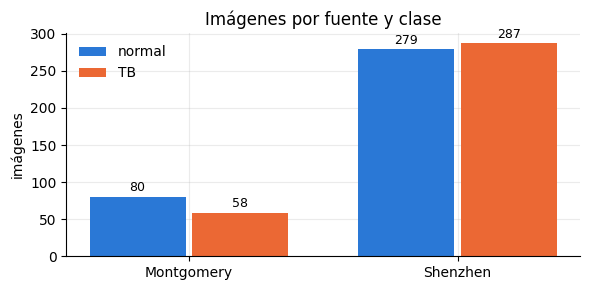

In [3]:
fig, ax = plt.subplots(figsize=(6, 3))
width = 0.38
x = np.arange(len(SOURCE_ORDER))
for k, (tb, name) in enumerate(CLASS_NAMES.items()):
    vals = [((index["source"] == s) & (index["tb"] == tb)).sum() for s in SOURCE_ORDER]
    bars = ax.bar(x + (k - 0.5) * width, vals, width * 0.94, color=CLASS_COLORS[tb], label=name)
    ax.bar_label(bars, padding=2, fontsize=9)
ax.set_xticks(x, [s.capitalize() for s in SOURCE_ORDER])
ax.set_ylabel("imágenes")
ax.set_title("Imágenes por fuente y clase")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

- Las 704 radiografías tienen máscara y lectura clínica, sin archivos huérfanos.
- La versión original de Shenzhen trae 662 imágenes (326 normales, 336 TB); la de Kaggle conserva solo las **566 que tienen máscara**. Montgomery está completo (138).
- Shenzhen aporta el 80 % de las imágenes. Las dos clases quedan casi balanceadas en el conjunto, pero la proporción de TB es distinta en cada fuente.

### 3. Metadatos clínicos

Cada fuente usa un formato distinto de lectura:

- Montgomery: `Patient's Sex: F` / `Patient's Age: 027Y` / hallazgo (texto libre del radiólogo).
- Shenzhen: `male 45yrs` / hallazgo, con variantes como `femal`, `male, 35yrs`, `male 35yr` o `1month`.

In [4]:
SEX_CODES = {"m": "M", "male": "M", "f": "F", "female": "F", "femal": "F", "o": "O"}
AGE_UNITS = {"y": 1, "m": 1 / 12, "d": 1 / 365}


def parse_reading(text: str, source: str) -> dict:
    """Extrae sexo, edad (años) y hallazgo de una lectura clínica."""
    lines = [line.strip() for line in text.splitlines() if line.strip()]
    if source == "montgomery":
        sex = re.search(r"Sex:\s*(\w)", text)
        age = re.search(r"Age:\s*(\d+)\s*([YMD])", text, re.I)
        finding = lines[2:]
    else:
        sex = re.match(r"(female|femal|male)", lines[0], re.I)
        age = re.search(r"(\d+)\s*(y|m|d)?", lines[0], re.I)
        finding = lines[1:]
    unit = (age.group(2) or "y").lower() if age else "y"
    return {
        "sex": SEX_CODES.get(sex.group(1).lower()) if sex else None,
        "age": round(int(age.group(1)) * AGE_UNITS[unit], 2) if age else np.nan,
        "finding": " | ".join(finding),
    }


meta = pd.DataFrame(
    [parse_reading((READ_DIR / f"{i}.txt").read_text(errors="replace"), s)
     for i, s in zip(index["image_id"], index["source"])]
)
index = pd.concat([index.drop(columns=["has_mask", "has_reading"]), meta], axis=1)

print("Lecturas sin sexo:", index["sex"].isna().sum(), "| sin edad:", index["age"].isna().sum())
print("Códigos de sexo:", index["sex"].value_counts().to_dict())
index.groupby("source").sample(3, random_state=SEED)[["image_id", "tb", "sex", "age", "finding"]]

Lecturas sin sexo: 0 | sin edad: 0
Códigos de sexo: {'M': 441, 'F': 262, 'O': 1}


,image_id,tb,sex,age,finding
655,MCUCXR_0150_1,1,M,32.0,extensive infiltrates bilaterally with large cavity in RUL and a moderate pleural effusion on the left. AF...
671,MCUCXR_0251_1,1,F,77.0,RUL fibrocavitary disease with volume loss and tracheal deviation to right; COPD scoliosis;
578,MCUCXR_0019_0,0,M,33.0,normal
396,CHNCXR_0465_1,1,M,24.0,Bilateral secondary PTB
302,CHNCXR_0371_1,1,M,40.0,PTB in the right upper field
435,CHNCXR_0526_1,1,M,63.0,bilateral PTB


#### 3.1 Pacientes repetidos

Algunas lecturas de Montgomery dicen *"same pt as MCUCXR_…"*: son controles del **mismo paciente** en momentos distintos. Si esas imágenes caen en particiones distintas habrá fuga de información, así que se asigna un `patient_id` común.

In [5]:
links = {
    row.image_id: re.findall(r"MCUCXR_\d{4}_\d", row.finding, re.I)
    for row in index.itertuples() if "same pt" in row.finding.lower()
}
patient_id = dict(zip(index["image_id"], index["image_id"]))
for image_id, others in links.items():
    group = sorted([image_id, *[o.upper() for o in others]])
    for member in group:
        patient_id[member] = min(patient_id[member], group[0])
# Una segunda pasada propaga cadenas (A igual a B, B igual a C)
for image_id in patient_id:
    patient_id[image_id] = patient_id[patient_id[image_id]]
index["patient_id"] = index["image_id"].map(patient_id)

repeated = index[index.duplicated("patient_id", keep=False)].sort_values("patient_id")
print(f"Imágenes con paciente repetido: {len(repeated)} en {repeated['patient_id'].nunique()} pacientes")
repeated[["image_id", "patient_id", "tb", "sex", "age", "finding"]]

Imágenes con paciente repetido: 5 en 2 pacientes


,image_id,patient_id,tb,sex,age,finding
648,MCUCXR_0113_1,MCUCXR_0113_1,1,F,84.0,bilateral miliary nodules diffusely with RML infiltrate and right pleural effusion; an old calcified granu...
649,MCUCXR_0117_1,MCUCXR_0113_1,1,F,85.0,stable CXR since 6M; off Rx since 6M (same pt as MCUCXR_0113_1)
656,MCUCXR_0162_1,MCUCXR_0162_1,1,M,49.0,RUL apical fibrotic disease with some calcifications; extensive irregular infiltrates in left lung with a ...
657,MCUCXR_0166_1,MCUCXR_0162_1,1,M,49.0,NO REPORT (same pt as MCUCXR_0162_1)
658,MCUCXR_0170_1,MCUCXR_0162_1,1,M,49.0,"CXR similar to prior views 1M and 2M ago with some slight improvement; on HRZ(E)x2 months, AFB smears neg ..."


#### 3.2 Sexo y edad

Sexo y edad no entran en los modelos. Se resumen de forma descriptiva para la tabla de datos del informe.

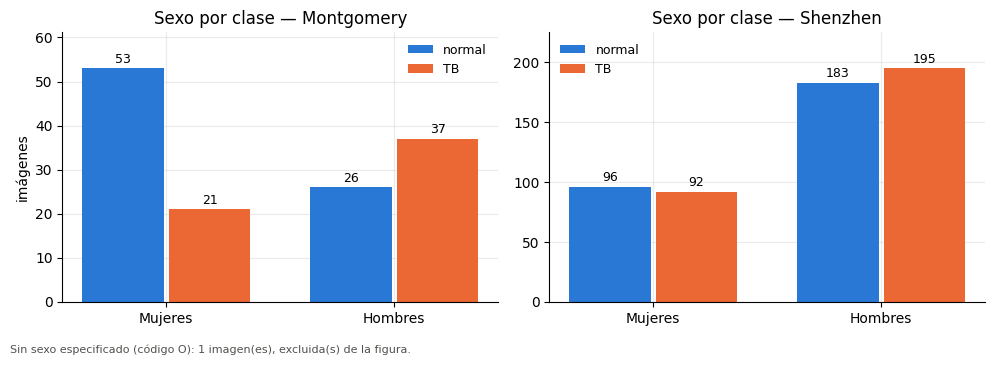

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
SEX_LABELS = {"F": "Mujeres", "M": "Hombres"}
width = 0.38
x = np.arange(len(SEX_LABELS))
for ax, source in zip(axes, SOURCE_ORDER):
    sub = index[index["source"] == source]
    for k, (tb, name) in enumerate(CLASS_NAMES.items()):
        vals = [((sub["sex"] == sex) & (sub["tb"] == tb)).sum() for sex in SEX_LABELS]
        bars = ax.bar(x + (k - 0.5) * width, vals, width * 0.94, color=CLASS_COLORS[tb], label=name)
        ax.bar_label(bars, padding=2, fontsize=9)
    ax.set_xticks(x, list(SEX_LABELS.values()))
    ax.set_ylim(0, ax.get_ylim()[1] * 1.1)
    ax.set_title(f"Sexo por clase — {source.capitalize()}")
    ax.legend(frameon=False, fontsize=9)
axes[0].set_ylabel("imágenes")

n_other = (~index["sex"].isin(SEX_LABELS)).sum()
fig.text(0.01, 0.005, f"Sin sexo especificado (código O): {n_other} imagen(es), excluida(s) de la figura.",
         fontsize=8, color="#52514e")
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()

In [7]:
demo = index.groupby(["source", "tb"]).agg(
    n=("image_id", "size"),
    mujeres=("sex", lambda s: (s == "F").sum()),
    hombres=("sex", lambda s: (s == "M").sum()),
    edad_mediana=("age", "median"),
    edad_q1=("age", lambda s: s.quantile(0.25)),
    edad_q3=("age", lambda s: s.quantile(0.75)),
).rename(index=CLASS_NAMES, level=1)
demo["% mujeres"] = (100 * demo["mujeres"] / demo["n"]).round(1)
demo["% hombres"] = (100 * demo["hombres"] / demo["n"]).round(1)
demo["edad, mediana (RIC)"] = [f"{m:.1f} ({a:.0f}-{b:.0f})" for m, a, b in demo[["edad_mediana", "edad_q1", "edad_q3"]].values]
demo[["n", "% mujeres", "% hombres", "edad, mediana (RIC)"]]

n  % mujeres  % hombres edad, mediana (RIC)
source     tb                                                   
montgomery normal   80       66.2       32.5        33.5 (22-46)
           TB       58       36.2       63.8        47.0 (32-61)
shenzhen   normal  279       34.4       65.6        32.0 (25-42)
           TB      287       32.1       67.9        34.0 (27-45)

- Se pudieron extraer sexo y edad de las 704 lecturas. Hay un paciente de Montgomery con sexo `O` (sin especificar).
- En Montgomery los casos TB son más a menudo hombres (64 % frente a 32,5 %) y mayores (mediana 47 frente a 33,5 años). En Shenzhen ambas clases tienen una composición parecida.
- Sexo y edad son propiedades del paciente: afectan por igual a todos los métodos de segmentación, así que no sesgan la comparación entre ellos. Se reportan solo como descripción del dataset.

#### 3.3 Hallazgos de los casos TB

In [8]:
KEYWORDS = {
    "activa": r"\bactive\b|\batb\b",
    "inactiva / cicatrices / antigua": r"inactive|scar|\bold\b|calcif|\bnatb\b",
    "secundaria": r"secondary|\bstb\b",
    "cavitación": r"cavit",
    "pleural / derrame": r"pleur|effusion",
    "bilateral": r"bilateral|both lungs",
    "campo / lóbulo superior": r"upper|\brul\b|\blul\b|apex|apical",
    "en tratamiento / mejoría": r"\brx\b|treat|improv|therapy",
    "otra patología mencionada": r"pneumonia|copd|\bpcp\b|\bchf\b|\bntm\b|pneumothorax|scoliosis|atelectasis",
}
tb_cases = index[index["tb"] == 1]
keyword_table = pd.DataFrame({
    source: {k: 100 * tb_cases.loc[tb_cases["source"] == source, "finding"].str.contains(rx, case=False, regex=True).mean()
             for k, rx in KEYWORDS.items()}
    for source in SOURCE_ORDER
}).round(1)
keyword_table.columns = [f"% casos TB {s.capitalize()}" for s in SOURCE_ORDER]
print("Lecturas normales con texto distinto de 'normal':",
      index.query("tb == 0")["finding"].str.lower().ne("normal").sum())
keyword_table

Lecturas normales con texto distinto de 'normal': 1


,% casos TB Montgomery,% casos TB Shenzhen
activa,31.0,1.0
inactiva / cicatrices / antigua,37.9,2.4
secundaria,0.0,30.0
cavitación,29.3,0.7
pleural / derrame,22.4,6.3
bilateral,10.3,35.5
campo / lóbulo superior,63.8,36.9
en tratamiento / mejoría,41.4,0.0
otra patología mencionada,12.1,2.8


- Las lecturas son heterogéneas. Montgomery usa texto libre que mezcla TB activa (31 %), inactiva o cicatricial (38 %) y casos en tratamiento o en mejoría (41 %). Un 12 % menciona otra patología (neumonía, PCP, micobacteria no tuberculosa, EPOC). Shenzhen usa fórmulas cortas ("right PTB", "bilateral secondary PTB") centradas en el lado y el campo afectado.
- Una lectura normal de Shenzhen dice "normale" (errata). No hay lecturas normales con hallazgos.
- **La etiqueta TB no es homogénea:** incluye TB curada o con cicatrices mínimas. Algunos positivos tendrán poca o ninguna lesión visible, y eso limita el rendimiento esperable de cualquier clasificador. Los subtipos no se pueden usar como etiqueta (el texto no está estandarizado), pero sirven para el análisis de errores.

### 4. Formato y adquisición

Se recorren las 704 imágenes **una sola vez**, en resolución completa. Para cada par imagen-máscara se registran:

- formato (tamaño, canales, tipo, niveles de gris usados);
- histogramas de 256 niveles de toda la imagen y del interior del pulmón, de los que se derivan estadísticas de primer orden equivalentes a las de pyradiomics;
- propiedades de la máscara (componentes, área, cociente entre pulmones);
- hash exacto (md5 de los píxeles) para buscar duplicados;
- fracción de píxeles negros y saturados (bordes, marcadores);
- miniatura de 256×256 de la máscara para la máscara promedio.

In [9]:
def analyze(image_id: str):
    raw = cv2.imread(str(IMG_DIR / f"{image_id}.png"), cv2.IMREAD_UNCHANGED)
    mask_raw = cv2.imread(str(mask_path(image_id)), cv2.IMREAD_GRAYSCALE)
    channels = 1 if raw.ndim == 2 else raw.shape[2]
    same_channels = channels == 1 or all(np.array_equal(raw[..., 0], raw[..., c]) for c in range(1, channels))
    gray = raw if raw.ndim == 2 else cv2.cvtColor(raw, cv2.COLOR_BGR2GRAY)
    lung = mask_raw > 127
    h, w = gray.shape

    hist_full = np.bincount(gray.ravel(), minlength=256)
    hist_lung = np.bincount(gray[lung], minlength=256)

    # Componentes de la máscara: las dos más grandes son los pulmones
    n_cc, _, cc_stats, cc_centroids = cv2.connectedComponentsWithStats(lung.astype(np.uint8), connectivity=8)
    areas = cc_stats[1:, cv2.CC_STAT_AREA]
    order = np.argsort(areas)[::-1][:2]
    # En la radiografía PA el pulmón derecho del paciente aparece a la izquierda de la imagen
    if len(order) == 2:
        right, left = sorted(order, key=lambda k: cc_centroids[1 + k][0])
        rl_ratio = areas[right] / areas[left]
    else:
        rl_ratio = np.nan
    ys, xs = np.nonzero(lung[:: 4, :: 4])

    record = {
        "image_id": image_id,
        "height": h, "width": w,
        "channels": channels, "same_channels": same_channels,
        "dtype": str(raw.dtype), "n_levels": int((hist_full > 0).sum()),
        "mask_shape_ok": mask_raw.shape == gray.shape,
        "mask_binary": bool(np.isin(np.unique(mask_raw), [0, 255]).all()),
        # Componentes con al menos 1 % del área pulmonar; el resto son puntos sueltos
        "n_components": int((areas >= 0.01 * lung.sum()).sum()),
        "n_specks": int((areas < 0.01 * lung.sum()).sum()),
        "lung_area_frac": lung.mean(),
        "rl_ratio": rl_ratio,
        "bbox_top": ys.min() * 4 / h, "bbox_bottom": ys.max() * 4 / h,
        "bbox_left": xs.min() * 4 / w, "bbox_right": xs.max() * 4 / w,
        "black_frac": hist_full[:6].sum() / gray.size,
        "saturated_frac": hist_full[250:].sum() / gray.size,
        "md5": hashlib.md5(gray.tobytes()).hexdigest(),
    }
    mask_thumb = cv2.resize(lung.astype(np.uint8) * 255, (THUMB, THUMB), interpolation=cv2.INTER_AREA)
    return record, hist_full, hist_lung, mask_thumb


# cv2 libera el GIL al leer PNG: unos pocos hilos aceleran la pasada sin disparar la memoria
with ThreadPoolExecutor(max_workers=4) as pool:
    results = list(tqdm(pool.map(analyze, index["image_id"]), total=len(index), desc="Analizando imágenes"))

records, hists_full, hists_lung, mask_thumbs = zip(*results)
img_stats = pd.DataFrame(records)
hists_full, hists_lung = np.stack(hists_full), np.stack(hists_lung)
mask_thumbs = np.stack(mask_thumbs)
index = index.merge(img_stats, on="image_id")
index["orientation"] = np.where(index["height"] >= index["width"], "vertical", "horizontal")
index.shape

Analizando imágenes:   0%|          | 0/704 [00:00<?, ?it/s]

(704, 27)

In [10]:
fmt = index.groupby("source").agg(
    imagenes=("image_id", "size"),
    canales=("channels", lambda s: sorted(s.unique())),
    canales_identicos=("same_channels", "mean"),
    dtype=("dtype", lambda s: sorted(s.unique())),
    niveles_min=("n_levels", "min"),
    niveles_max=("n_levels", "max"),
    alto_min=("height", "min"), alto_max=("height", "max"),
    ancho_min=("width", "min"), ancho_max=("width", "max"),
    mascara_mismo_tamano=("mask_shape_ok", "mean"),
    mascara_binaria=("mask_binary", "mean"),
)
fmt.T

source,montgomery,shenzhen
imagenes,138,566
canales,[1],[3]
canales_identicos,1.0,1.0
dtype,[uint8],[uint8]
niveles_min,253,244
niveles_max,256,256
alto_min,4020,989
alto_max,4892,3001
ancho_min,4020,1225
ancho_max,4892,3001


- **Canales:** Montgomery viene en un canal y Shenzhen en tres canales idénticos. Se pueden leer en escala de grises sin perder información, como ya hace `prepare.py`.
- **Profundidad:** ambas fuentes vienen en 8 bits y usan casi todos los niveles (244-256). El ReadMe de Montgomery habla de 12 bits, así que esta versión ya fue reducida a 8.
- **Tamaño:** Montgomery mide siempre 4020×4892 (vertical u horizontal), con un píxel de 0,0875 mm. Shenzhen varía entre ~1000 y 3000 px de lado y su ReadMe no informa el espaciado de píxel. Las características de primer orden dependen poco del tamaño, pero las de forma y textura sí: antes de extraer características hay que fijar una resolución común. El 512×512 de `prepare.py` deforma la proporción.

#### 4.1 Ejemplos con su máscara

Tres radiografías normales y tres con TB por fuente, con el contorno de la máscara manual. En Montgomery se incluye `MCUCXR_0182_1` (TB pleural), el ejemplo de la presentación de U-Net.

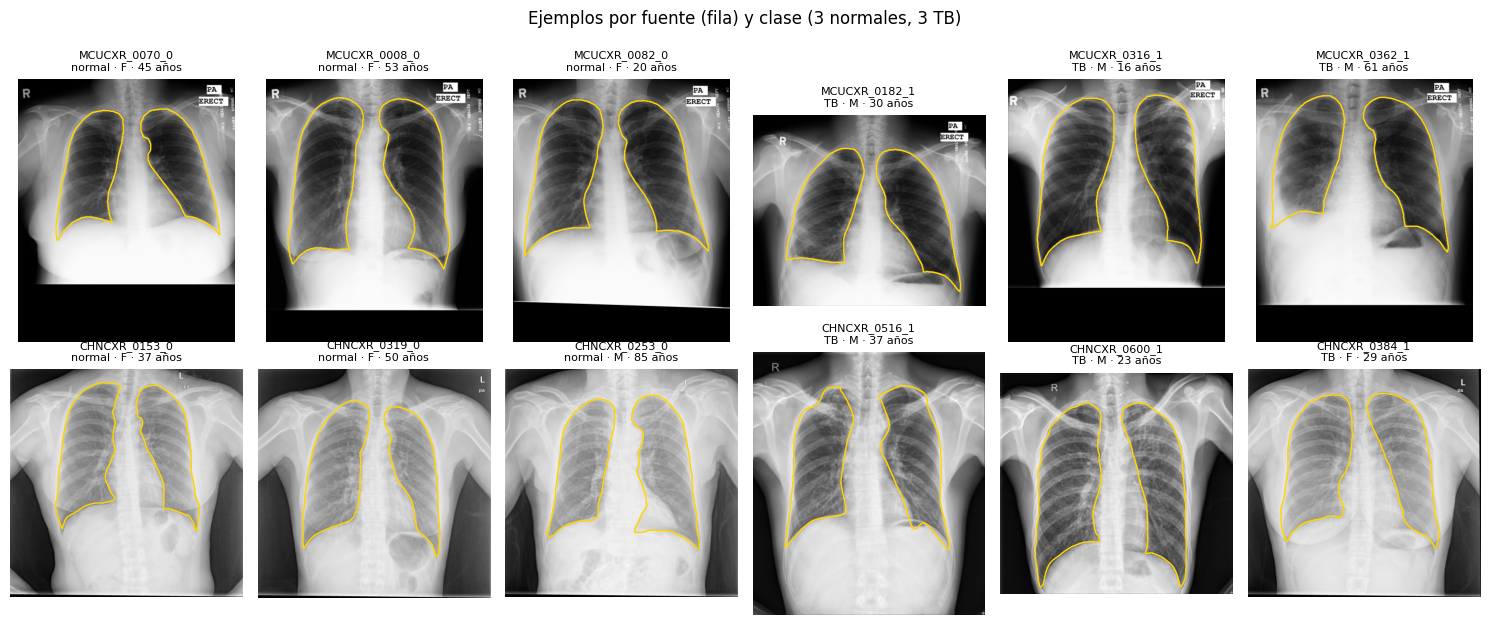

In [11]:
def load_pair(image_id: str, size: int = 512):
    img = cv2.imread(str(IMG_DIR / f"{image_id}.png"), cv2.IMREAD_GRAYSCALE)
    mask = cv2.imread(str(mask_path(image_id)), cv2.IMREAD_GRAYSCALE)
    scale = size / max(img.shape)
    dsize = (round(img.shape[1] * scale), round(img.shape[0] * scale))
    return cv2.resize(img, dsize, interpolation=cv2.INTER_AREA), cv2.resize(mask, dsize, interpolation=cv2.INTER_AREA) > 127


def show_with_mask(ax, image_id, title=None):
    img, mask = load_pair(image_id)
    ax.imshow(img, cmap="gray")
    ax.contour(mask, levels=[0.5], colors=["#ffd400"], linewidths=1)
    ax.set_title(title or image_id, fontsize=8)
    ax.axis("off")


examples = []
for source in SOURCE_ORDER:
    for tb in CLASS_NAMES:
        ids = index.query("source == @source and tb == @tb")["image_id"].to_numpy()
        chosen = list(rng.choice(ids, 3, replace=False))
        if source == "montgomery" and tb == 1 and "MCUCXR_0182_1" not in chosen:
            chosen[0] = "MCUCXR_0182_1"
        examples.append((source, tb, chosen))

fig, axes = plt.subplots(2, 6, figsize=(15, 6.2))
for r, source in enumerate(SOURCE_ORDER):
    ids = [(tb, i) for s, tb, chosen in examples if s == source for i in chosen]
    for c, (tb, image_id) in enumerate(ids):
        row = index.set_index("image_id").loc[image_id]
        show_with_mask(axes[r, c], image_id, f"{image_id}\n{CLASS_NAMES[tb]} · {row['sex']} · {row['age']:.0f} años")
plt.suptitle("Ejemplos por fuente (fila) y clase (3 normales, 3 TB)", y=1.0)
plt.tight_layout()
plt.show()

### 5. Máscaras pulmonares

Las máscaras de Montgomery se dibujaron bajo supervisión de un radiólogo: incluyen ambos pulmones, **excluyen la zona detrás del corazón** y siguen el ángulo costofrénico. Cuando la patología deforma el pulmón, se dibuja el borde inferido. Se revisa si son consistentes y si dependen de la clase o de la fuente.

In [12]:
print("Componentes principales (≥ 1 % del área pulmonar) por máscara:")
print(pd.crosstab(index["n_components"], index["source"]))
print("\nMáscaras con puntos sueltos (< 1 % del área):",
      (index["n_specks"] > 0).groupby(index["source"]).sum().to_dict(),
      "| área máxima de un punto suelto: casi siempre 1-2 píxeles")

mask_cols = ["lung_area_frac", "rl_ratio", "bbox_top", "bbox_bottom"]
index.groupby(["source", "tb"])[mask_cols].median().rename(index=CLASS_NAMES, level=1).round(3)

Componentes principales (≥ 1 % del área pulmonar) por máscara:
source        montgomery  shenzhen
n_components                      
2                    138       565
3                      0         1

Máscaras con puntos sueltos (< 1 % del área): {'montgomery': 2, 'shenzhen': 104} | área máxima de un punto suelto: casi siempre 1-2 píxeles


lung_area_frac  rl_ratio  bbox_top  bbox_bottom
source     tb                                                     
montgomery normal           0.246     1.156     0.086        0.715
           TB               0.263     1.163     0.097        0.737
shenzhen   normal           0.228     1.193     0.129        0.778
           TB               0.272     1.154     0.120        0.841

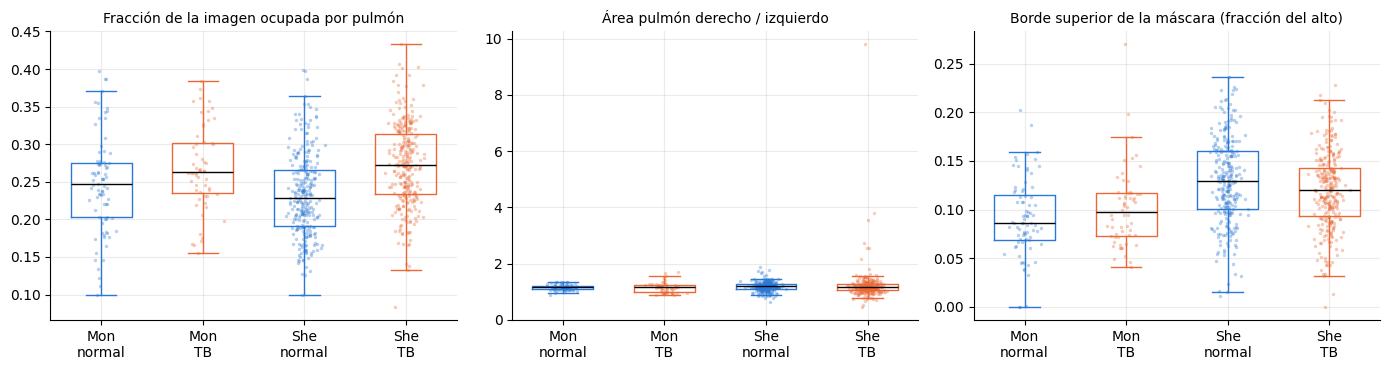

AUC TB vs normal,Montgomery,Shenzhen
Fracción de la imagen ocupada por pulmón,0.60,0.71
Área pulmón derecho / izquierdo,0.51,0.55
Borde superior de la máscara (fracción del alto),0.55,0.56


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
panels = [("lung_area_frac", "Fracción de la imagen ocupada por pulmón"),
          ("rl_ratio", "Área pulmón derecho / izquierdo"),
          ("bbox_top", "Borde superior de la máscara (fracción del alto)")]
positions = {(s, tb): i for i, (s, tb) in enumerate((s, tb) for s in SOURCE_ORDER for tb in CLASS_NAMES)}
for ax, (col, title) in zip(axes, panels):
    for (source, tb), pos in positions.items():
        vals = index.query("source == @source and tb == @tb")[col].dropna()
        ax.boxplot(vals, positions=[pos], widths=0.6, showfliers=False,
                   medianprops={"color": "black"}, boxprops={"color": CLASS_COLORS[tb]},
                   whiskerprops={"color": CLASS_COLORS[tb]}, capprops={"color": CLASS_COLORS[tb]})
        jitter = rng.normal(0, 0.07, len(vals))
        ax.scatter(pos + jitter, vals, s=6, alpha=0.35, color=CLASS_COLORS[tb], linewidth=0)
    ax.set_xticks(list(positions.values()),
                  [f"{s[:3].capitalize()}\n{CLASS_NAMES[tb]}" for s, tb in positions])
    ax.set_title(title, fontsize=10)
plt.tight_layout()
plt.show()

mask_auc = pd.DataFrame({
    source.capitalize(): {title: separability(s.loc[s[col].notna(), "tb"], s[col].dropna()) for col, title in panels}
    for source in SOURCE_ORDER
    for s in [index[index["source"] == source]]
})
mask_auc.columns.name = "AUC TB vs normal"
mask_auc.round(2)

- Todas las máscaras tienen dos componentes principales (los dos pulmones), salvo `CHNCXR_0361_1`, donde el líquido encapsulado divide el pulmón izquierdo. 104 máscaras de Shenzhen y 2 de Montgomery tienen además **puntos sueltos de 1-2 píxeles**: hay que limpiarlas conservando las dos componentes mayores antes de usarlas como referencia.
- En Shenzhen el área pulmonar relativa es mayor en TB (mediana 0,272 frente a 0,228; AUC 0,71) y el borde inferior de la máscara queda más abajo en la imagen (0,84 frente a 0,78). Esto apunta a un **encuadre distinto** entre las radiografías TB y las normales de Shenzhen, más que a pulmones más grandes. En Montgomery la diferencia es menor (AUC 0,60). El cociente entre pulmones y el borde superior no separan las clases en ninguna fuente (AUC ≤ 0,56).

#### 5.1 Máscaras atípicas y máscara promedio

In [14]:
q1, q3 = index["lung_area_frac"].quantile([0.25, 0.75])
iqr = q3 - q1
atypical = index[
    (index["n_components"] != 2)
    | (index["lung_area_frac"] < q1 - 1.5 * iqr) | (index["lung_area_frac"] > q3 + 1.5 * iqr)
    | (index["rl_ratio"] < 0.6) | (index["rl_ratio"] > 1.8)
]
print(f"Máscaras atípicas: {len(atypical)}")
atypical[["image_id", "tb", "n_components", "n_specks", "lung_area_frac", "rl_ratio", "finding"]].round(3)

Máscaras atípicas: 12


,image_id,tb,n_components,n_specks,lung_area_frac,rl_ratio,finding
255,CHNCXR_0303_0,0,2,0,0.099,1.868,normal
290,CHNCXR_0339_1,1,2,0,0.433,0.754,STB | ATB
292,CHNCXR_0361_1,1,3,4,0.199,3.557,"Bilateral secondary PTB, left encapsulated intrathoracic fluid"
301,CHNCXR_0370_1,1,2,0,0.138,2.735,"bilateral PTB, with left pleural effusion"
312,CHNCXR_0381_1,1,2,0,0.183,2.162,"left PTB,left pleurisy"
386,CHNCXR_0455_1,1,2,0,0.084,0.951,right secondary PTB with bilateral pleurisy
422,CHNCXR_0513_1,1,2,0,0.392,0.521,Right PTB
435,CHNCXR_0526_1,1,2,0,0.233,2.540,bilateral PTB
472,CHNCXR_0569_1,1,2,0,0.259,2.563,bilateral PTB
506,CHNCXR_0603_1,1,2,0,0.196,9.795,bilateral PTB


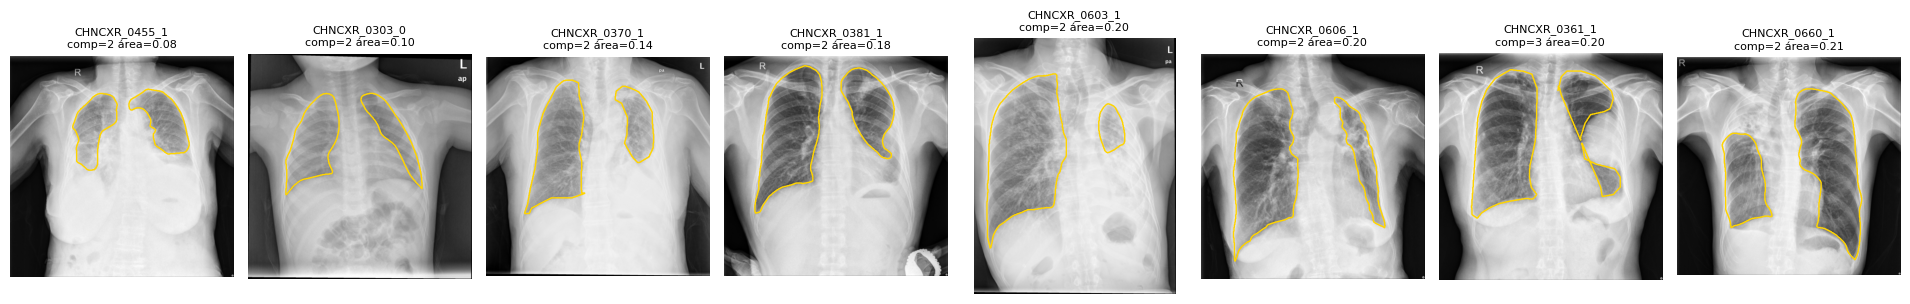

In [15]:
show = atypical.sort_values("lung_area_frac")["image_id"].tolist()[:8]
if show:
    fig, axes = plt.subplots(1, len(show), figsize=(2.4 * len(show), 3))
    for ax, image_id in zip(np.atleast_1d(axes), show):
        row = index.set_index("image_id").loc[image_id]
        show_with_mask(ax, image_id, f"{image_id}\ncomp={row['n_components']} área={row['lung_area_frac']:.2f}")
    plt.tight_layout()
    plt.show()

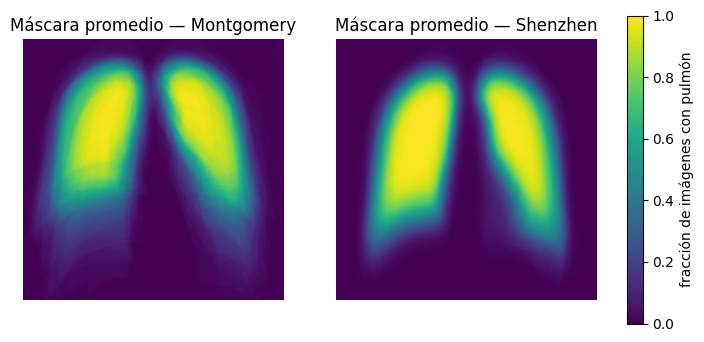

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
for ax, source in zip(axes, SOURCE_ORDER):
    sel = (index["source"] == source).to_numpy()
    im = ax.imshow(mask_thumbs[sel].mean(axis=0) / 255, cmap="viridis", vmin=0, vmax=1)
    ax.set_title(f"Máscara promedio — {source.capitalize()}")
    ax.axis("off")
fig.colorbar(im, ax=axes, fraction=0.025, label="fracción de imágenes con pulmón")
plt.show()

- Hay 12 máscaras atípicas, 11 de ellas de casos TB de Shenzhen con derrame, atelectasia o pleuritis. En esas máscaras se **delimita solo el pulmón aireado visible**. El ReadMe de Montgomery, en cambio, indica que ante patología severa se dibuja el borde *inferido*. Las máscaras de Shenzhen no vienen de la NLM: se agregaron en la versión de Kaggle y no traen documentación de su convención. Así, **la convención de anotación difiere entre fuentes**, y eso afecta directamente el área y las características extraídas en los casos más graves.
- La máscara promedio muestra la misma disposición en ambas fuentes, pero en Montgomery los pulmones aparecen un poco más arriba en la imagen.

### 6. Intensidades: imagen completa vs pulmón

Esta sección es la más cercana a la pregunta del proyecto. Las características radiómicas de **primer orden** resumen el histograma de intensidades dentro de una región (media, desviación, percentiles, asimetría, curtosis, entropía, uniformidad). Aquí se calculan con los histogramas de la sección 4 de dos formas: en **toda la imagen** y **dentro de la máscara manual**. Así se ve si restringir el análisis al pulmón cambia la capacidad de separar TB de normal.

> pyradiomics discretiza las intensidades con `binWidth=25` antes de calcular entropía y uniformidad. Aquí se usan los 256 niveles, así que los valores absolutos difieren, pero las tendencias son comparables.

In [17]:
LEVELS = np.arange(256)


def first_order(hist: np.ndarray) -> dict:
    """Estadísticas de primer orden a partir de un histograma de 256 niveles."""
    p = hist / hist.sum()
    mean = (p * LEVELS).sum()
    var = (p * (LEVELS - mean) ** 2).sum()
    cdf = np.cumsum(p)
    pct = {q: np.searchsorted(cdf, q / 100) for q in (10, 25, 50, 75, 90)}
    nz = p[p > 0]
    return {
        "media": mean,
        "desviacion": np.sqrt(var),
        "p10": pct[10], "mediana": pct[50], "p90": pct[90],
        "rango_iq": pct[75] - pct[25],
        "asimetria": (p * (LEVELS - mean) ** 3).sum() / var**1.5,
        "curtosis": (p * (LEVELS - mean) ** 4).sum() / var**2,
        "entropia": -(nz * np.log2(nz)).sum(),
        "uniformidad": (p**2).sum(),
    }


FEATURES = list(first_order(hists_full[0]))
hists_out = hists_full - hists_lung
feat = {
    "imagen completa": pd.DataFrame([first_order(h) for h in hists_full]),
    "fuera del pulmón": pd.DataFrame([first_order(h) for h in hists_out]),
    "pulmón": pd.DataFrame([first_order(h) for h in hists_lung]),
}
pd.concat(feat, axis=1).groupby([index["source"], index["tb"].map(CLASS_NAMES)]).median().T.round(2)

source                       montgomery         shenzhen        
tb                                   TB  normal       TB  normal
imagen completa  media           114.69  115.47   150.54  160.99
                 desviacion       83.27   82.28    64.34   63.38
                 p10               0.00    0.00    50.00   48.00
                 mediana         111.00  113.50   168.00  181.00
                 p90             233.50  236.00   221.00  225.00
                 rango_iq        150.00  148.00    99.00   77.00
                 asimetria         0.13    0.10    -0.71   -1.05
                 curtosis          1.70    1.69     2.47    3.10
                 entropia          7.30    7.12     7.55    7.42
                 uniformidad       0.02    0.03     0.01    0.01
fuera del pulmón media           127.48  127.38   160.56  164.09
                 desviacion       90.69   89.21    70.59   70.50
                 p10               0.00    0.00    21.00   33.00
                 mediana         144.00  152.50   190.00  196.00
                 p90             241.00  242.00   224.00  227.00
                 rango_iq        182.50  170.50    86.00   85.00
                 asimetria        -0.22   -0.25    -1.10   -1.10
                 curtosis          1.62    1.70     2.82    2.79
                 entropia          6.88    6.55     7.28    7.24
                 uniformidad       0.04    0.05     0.01    0.01
pulmón           media            78.30   80.55   124.13  154.22
                 desviacion       40.34   41.02    33.03   25.00
                 p10              34.00   34.50    82.00  125.00
                 mediana          69.50   71.00   120.00  152.00
                 p90             138.50  141.50   174.00  187.00
                 rango_iq         52.00   52.00    45.00   33.00
                 asimetria         0.94    1.01     0.46    0.38
                 curtosis          3.32    3.68     2.87    2.92
                 entropia          7.16    7.20     7.02    6.65
                 uniformidad       0.01    0.01     0.01    0.01

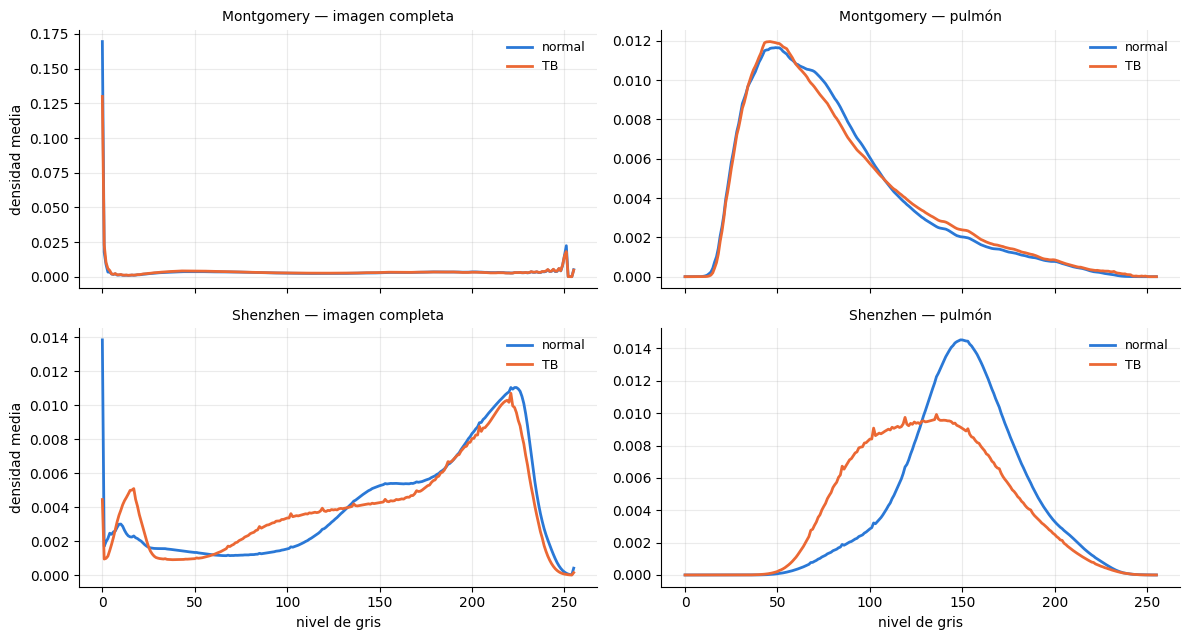

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(12, 6.5), sharex=True)
for r, source in enumerate(SOURCE_ORDER):
    for c, (region, hists) in enumerate([("imagen completa", hists_full), ("pulmón", hists_lung)]):
        ax = axes[r, c]
        for tb, name in CLASS_NAMES.items():
            sel = ((index["source"] == source) & (index["tb"] == tb)).to_numpy()
            dens = hists[sel] / hists[sel].sum(axis=1, keepdims=True)
            ax.plot(LEVELS, dens.mean(axis=0), lw=2, color=CLASS_COLORS[tb], label=name)
        ax.set_title(f"{source.capitalize()} — {region}", fontsize=10)
        ax.legend(frameon=False, fontsize=9)
for ax in axes[1]:
    ax.set_xlabel("nivel de gris")
for ax in axes[:, 0]:
    ax.set_ylabel("densidad media")
plt.tight_layout()
plt.show()

#### 6.1 Capacidad discriminativa univariada

Para cada estadística se calcula el AUC al separar TB de normal en tres regiones: imagen completa, **fuera del pulmón** y pulmón. La región fuera del pulmón funciona como control: la TB pulmonar no debería cambiar la intensidad del abdomen, los hombros o el fondo. Si esa región también separa las clases, una parte de la señal viene de la adquisición y no de la enfermedad.

Para cada región y estadística Se reporta `max(AUC, 1 − AUC)`, que mide la separabilidad sin importar la dirección (0,5 = sin señal). Hay cuatro comparaciones:

1. TB vs normal en todo el conjunto.
2. TB vs normal solo en Montgomery.
3. TB vs normal solo en Shenzhen.
4. Montgomery vs Shenzhen (la **fuente**) con las mismas estadísticas.

Si la fuente se separa mucho mejor que la clase, un modelo entrenado con el conjunto combinado podría aprender el origen de la imagen en lugar de la enfermedad.

In [19]:
tasks = {
    "TB — conjunto": (np.ones(len(index), bool), index["tb"]),
    "TB — Montgomery": ((index["source"] == "montgomery").to_numpy(), index["tb"]),
    "TB — Shenzhen": ((index["source"] == "shenzhen").to_numpy(), index["tb"]),
    "fuente (Mont. vs Shen.)": (np.ones(len(index), bool), (index["source"] == "montgomery").astype(int)),
}
auc_rows = []
for task, (sel, y) in tasks.items():
    for region, df in feat.items():
        for f in FEATURES:
            auc_rows.append({"tarea": task, "región": region, "característica": f,
                             "AUC": separability(y[sel], df.loc[sel, f])})
auc = pd.DataFrame(auc_rows)
auc_table = (auc.pivot_table(index="característica", columns=["tarea", "región"], values="AUC")
             .loc[FEATURES, pd.MultiIndex.from_product([list(tasks), list(feat)])])
auc_table.round(2)

tarea            TB — conjunto                         TB — Montgomery  \
región         imagen completa fuera del pulmón pulmón imagen completa   
característica                                                           
media                     0.60             0.53   0.63            0.52   
desviacion                0.50             0.52   0.66            0.52   
p10                       0.51             0.53   0.63            0.52   
mediana                   0.61             0.55   0.63            0.52   
p90                       0.60             0.59   0.60            0.51   
rango_iq                  0.62             0.50   0.69            0.52   
asimetria                 0.63             0.50   0.52            0.55   
curtosis                  0.60             0.50   0.58            0.56   
entropia                  0.69             0.57   0.68            0.59   
uniformidad               0.71             0.61   0.69            0.59   

tarea                                    TB — Shenzhen                   \
región         fuera del pulmón pulmón imagen completa fuera del pulmón   
característica                                                            
media                      0.50   0.51            0.68             0.57   
desviacion                 0.51   0.53            0.54             0.51   
p10                        0.53   0.51            0.53             0.58   
mediana                    0.53   0.53            0.70             0.61   
p90                        0.51   0.52            0.64             0.61   
rango_iq                   0.50   0.59            0.71             0.53   
asimetria                  0.51   0.61            0.74             0.54   
curtosis                   0.52   0.66            0.69             0.53   
entropia                   0.59   0.52            0.74             0.57   
uniformidad                0.58   0.52            0.76             0.62   

tarea                 fuente (Mont. vs Shen.)                          
región         pulmón         imagen completa fuera del pulmón pulmón  
característica                                                         
media            0.74                    0.97             0.88   1.00  
desviacion       0.76                    0.99             0.93   0.94  
p10              0.74                    0.92             0.91   1.00  
mediana          0.74                    0.98             0.94   1.00  
p90              0.70                    0.78             0.88   0.96  
rango_iq         0.76                    0.98             0.89   0.84  
asimetria        0.58                    1.00             0.94   0.96  
curtosis         0.54                    0.96             0.86   0.85  
entropia         0.76                    0.61             0.70   0.85  
uniformidad      0.76                    0.84             0.90   0.78

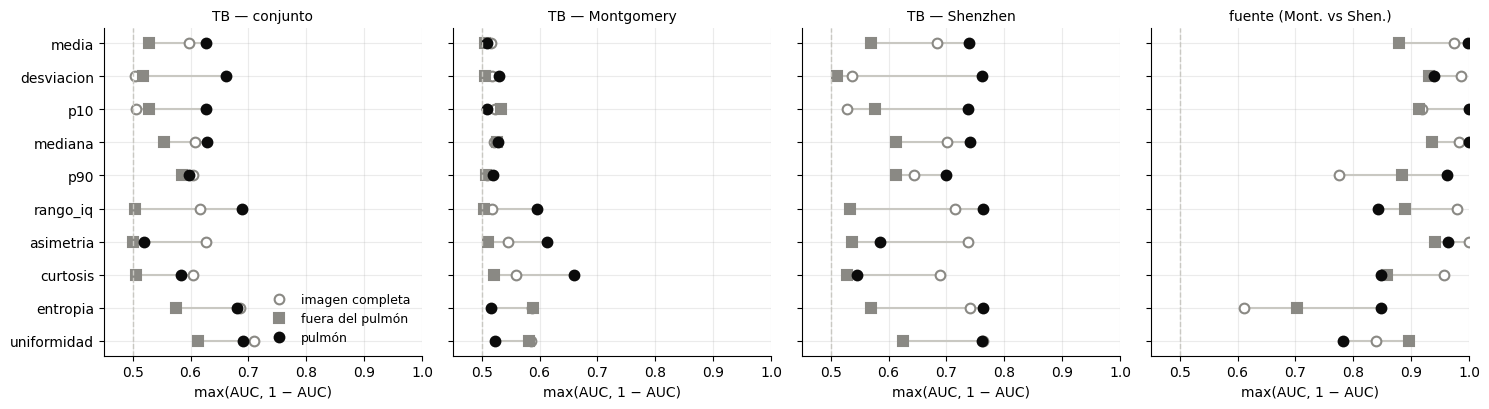

característica                               \
región                  fuera del pulmón imagen completa       pulmón   
tarea                                                                   
TB — conjunto                uniformidad     uniformidad  uniformidad   
TB — Montgomery                 entropia        entropia     curtosis   
TB — Shenzhen                uniformidad     uniformidad     entropia   
fuente (Mont. vs Shen.)        asimetria       asimetria          p10   

                                     AUC                            
región                  fuera del pulmón imagen completa    pulmón  
tarea                                                               
TB — conjunto                   0.612192        0.709039  0.689718  
TB — Montgomery                 0.588578        0.585991  0.658621  
TB — Shenzhen                   0.624618        0.762404  0.763803  
fuente (Mont. vs Shen.)         0.941082        0.999411       1.0

In [20]:
REGION_STYLE = {"imagen completa": dict(color="#8a8984", marker="o", mfc="white"),
                "fuera del pulmón": dict(color="#8a8984", marker="s", mfc="#8a8984"),
                "pulmón": dict(color="#0b0b0b", marker="o", mfc="#0b0b0b")}
fig, axes = plt.subplots(1, len(tasks), figsize=(15, 4.2), sharey=True)
y_pos = np.arange(len(FEATURES))
for ax, task in zip(axes, tasks):
    for f_i, f in enumerate(FEATURES):
        vals = auc_table.loc[f, task]
        ax.plot([vals.min(), vals.max()], [f_i, f_i], color="#c9c8c2", lw=1.5, zorder=1)
    for region, style in REGION_STYLE.items():
        ax.plot(auc_table[(task, region)].values, y_pos, ls="none", ms=7, mew=1.5, label=region, **style)
    ax.axvline(0.5, color="#c9c8c2", lw=1, ls="--")
    ax.set_xlim(0.45, 1.0)
    ax.set_title(task, fontsize=10)
    ax.set_xlabel("max(AUC, 1 − AUC)")
axes[0].set_yticks(y_pos, FEATURES)
axes[0].invert_yaxis()
axes[0].legend(frameon=False, fontsize=9, loc="lower right")
plt.tight_layout()
plt.show()

best = auc.loc[auc.groupby(["tarea", "región"])["AUC"].idxmax()]
best.pivot(index="tarea", columns="región", values=["característica", "AUC"]).loc[list(tasks)].round(2)

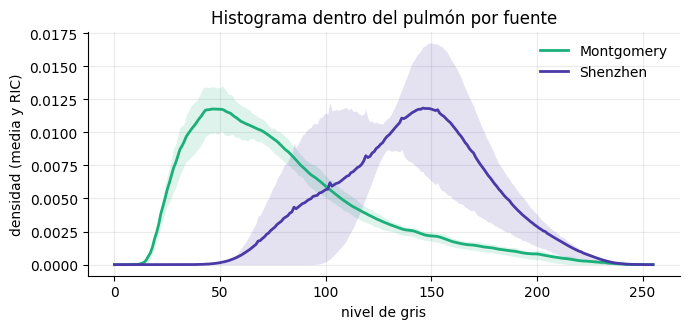

In [21]:
fig, ax = plt.subplots(figsize=(7, 3.4))
for source in SOURCE_ORDER:
    sel = (index["source"] == source).to_numpy()
    dens = hists_lung[sel] / hists_lung[sel].sum(axis=1, keepdims=True)
    ax.plot(LEVELS, dens.mean(axis=0), lw=2, color=SOURCE_COLORS[source], label=source.capitalize())
    ax.fill_between(LEVELS, *np.percentile(dens, [25, 75], axis=0), color=SOURCE_COLORS[source], alpha=0.15, lw=0)
ax.set_xlabel("nivel de gris")
ax.set_ylabel("densidad (media y RIC)")
ax.set_title("Histograma dentro del pulmón por fuente")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

- **Montgomery:** casi no hay señal univariada (AUC ≤ 0,66). Restringir al pulmón ayuda un poco: curtosis 0,56 → 0,66 y asimetría 0,55 → 0,61.
- **Shenzhen:** la señal es mayor (AUC de hasta 0,76 en el pulmón) y la intensidad media del pulmón en TB es mucho menor (124 frente a 154). Pero la región *fuera del pulmón* también separa las clases (AUC de hasta 0,62), y el histograma medio de TB tiene una forma distinta (picos regulares). Parte de la señal de Shenzhen viene de la **adquisición o el posprocesado**, no solo de la enfermedad (ver sección 7).
- **Fuente:** las estadísticas del pulmón separan Montgomery de Shenzhen casi perfectamente (AUC ≈ 1,0 con la media, la mediana o el p10). Como el 80 % de las imágenes son de Shenzhen, el conjunto combinado hereda sus sesgos.
- **Para la propuesta:** cambiar la región cambia la capacidad discriminativa de cada característica (por ejemplo, la desviación en Shenzhen pasa de 0,54 en la imagen completa a 0,76 en el pulmón). Esto respalda la premisa de que la segmentación condiciona la calidad de las características.

### 7. Calidad de imagen y duplicados

#### 7.1 Duplicados

El md5 de los píxeles detecta copias exactas aunque el PNG esté codificado distinto.

In [22]:
exact = index[index.duplicated("md5", keep=False)]
print(f"Grupos de duplicados exactos: {exact['md5'].nunique()} ({len(exact)} imágenes)")
print(f"{len(index)} imágenes de {index['patient_id'].nunique()} pacientes")

Grupos de duplicados exactos: 0 (0 imágenes)
704 imágenes de 701 pacientes


- No hay duplicados exactos.
- La única repetición conocida son los 2 pacientes de Montgomery con varias radiografías (sección 3.1), agrupados con `patient_id`.

#### 7.2 Señales de adquisición

Se miden tres propiedades que dependen del equipo y del posprocesado, no de la enfermedad:

- **fracción de píxeles negros** (≤ 5): bordes y relleno;
- **fracción de píxeles saturados** (≥ 250): marcadores y zonas quemadas;
- **rugosidad del histograma**: diferencia relativa entre el histograma y su versión suavizada con un filtro de mediana. Detecta patrones de "peine" propios del reescalado de contraste, como los picos del histograma medio de TB en Shenzhen (sección 6).

Si alguna separa TB de normal, un modelo puede aprender la adquisición en lugar de la lesión. Además, como estas señales están en zonas concretas de la imagen (bordes, fondo), un método de segmentación que incluya más de esas zonas capturará más de ellas: **pueden crear diferencias entre segmentaciones que no vienen de la calidad pulmonar**.

In [23]:
from scipy.signal import medfilt


def roughness(hist: np.ndarray) -> float:
    h = hist.astype(float)
    return np.abs(h - medfilt(h, 5)).sum() / h.sum()


index["hist_roughness"] = [roughness(h) for h in hists_full]

ACQ = {"black_frac": "píxeles negros", "saturated_frac": "píxeles saturados", "hist_roughness": "rugosidad del histograma"}
acq_table = pd.DataFrame({
    name: {
        (source.capitalize(), label): value
        for source in SOURCE_ORDER
        for s in [index[index["source"] == source]]
        for label, value in [
            ("mediana normal", s.loc[s["tb"] == 0, col].median()),
            ("mediana TB", s.loc[s["tb"] == 1, col].median()),
            ("AUC TB vs normal", separability(s["tb"], s[col])),
        ]
    }
    for col, name in ACQ.items()
}).T
acq_table.round(3)

Montgomery                              \
                         mediana normal mediana TB AUC TB vs normal   
píxeles negros                    0.184      0.172            0.546   
píxeles saturados                 0.038      0.031            0.533   
rugosidad del histograma          0.222      0.190            0.585   

                               Shenzhen                              
                         mediana normal mediana TB AUC TB vs normal  
píxeles negros                    0.017      0.006            0.755  
píxeles saturados                 0.001      0.000            0.802  
rugosidad del histograma          0.014      0.010            0.740

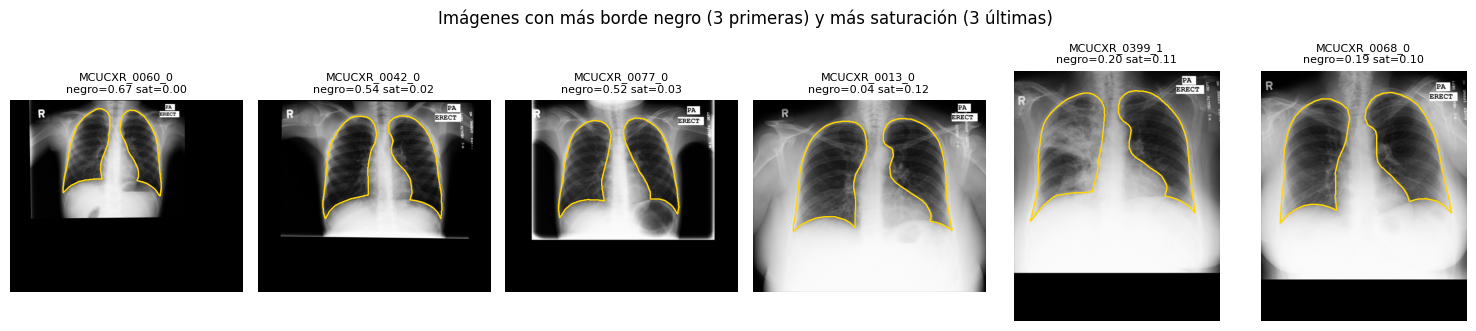

In [24]:
extremes = pd.concat([index.nlargest(3, "black_frac"), index.nlargest(3, "saturated_frac")])
fig, axes = plt.subplots(1, len(extremes), figsize=(2.5 * len(extremes), 3.2))
for ax, row in zip(axes, extremes.itertuples()):
    show_with_mask(ax, row.image_id, f"{row.image_id}\nnegro={row.black_frac:.2f} sat={row.saturated_frac:.2f}")
plt.suptitle("Imágenes con más borde negro (3 primeras) y más saturación (3 últimas)", y=1.02)
plt.tight_layout()
plt.show()

- **Montgomery** tiene bandas negras de relleno (mediana ~18 % de la imagen, hasta 67 %), además de marcadores "R" y "PA ERECT". Estos elementos contaminan cualquier característica calculada sobre la imagen completa, pero no afectan a la región pulmonar.
- **Shenzhen:** la fracción de píxeles saturados (AUC 0,80), la de píxeles negros (0,76) y la rugosidad del histograma (0,74) separan TB de normal **tanto o más que las intensidades del pulmón**. Son propiedades del equipo y del posprocesado, no de la enfermedad: las radiografías TB y las normales de Shenzhen parecen haberse adquirido o procesado de forma distinta.
- En Montgomery ninguna de estas métricas separa las clases (AUC 0,53-0,58).

### 8. Índice de salida

Se guarda un índice con una fila por imagen para las fases siguientes (segmentación, extracción de características y protocolo de entrenamiento). No incluye particiones: los folds se definen con el protocolo de entrenamiento, agrupando por `patient_id`.

In [25]:
INDEX_COLS = ["image_id", "patient_id", "source", "tb", "sex", "age", "finding", "height", "width",
              "orientation", "channels", "n_components", "n_specks", "lung_area_frac", "rl_ratio",
              "black_frac", "hist_roughness", "md5"]
out = index[INDEX_COLS].copy()
out["lung_area_frac"] = out["lung_area_frac"].round(4)
out["rl_ratio"] = out["rl_ratio"].round(4)
out["black_frac"] = out["black_frac"].round(4)
out["hist_roughness"] = out["hist_roughness"].round(4)
MS_INDEX_CSV.parent.mkdir(parents=True, exist_ok=True)
out.to_csv(MS_INDEX_CSV, index=False)
print(f"Guardado {MS_INDEX_CSV.relative_to(MS_INDEX_CSV.parents[2])}: {out.shape}")
out.head()

Guardado data/metadata/montgomery_shenzhen_index.csv: (704, 18)


,image_id,patient_id,source,tb,sex,age,finding,height,width,orientation,channels,n_components,n_specks,lung_area_frac,rl_ratio,black_frac,hist_roughness,md5
0,CHNCXR_0001_0,CHNCXR_0001_0,shenzhen,0,M,45.0,normal,2919,3000,horizontal,3,2,0,0.2455,0.9594,0.0541,0.0303,cb9e6ba843d512a5719fef8f6a4cd834
1,CHNCXR_0002_0,CHNCXR_0002_0,shenzhen,0,M,63.0,normal,2951,3000,horizontal,3,2,2,0.2167,0.8336,0.0597,0.0324,c238805cf0210c984a6b81bb908fb18b
2,CHNCXR_0003_0,CHNCXR_0003_0,shenzhen,0,F,48.0,normal,2945,2987,horizontal,3,2,2,0.2393,1.0501,0.0094,0.0111,c1236e360b37974a4170f5f209836c39
3,CHNCXR_0004_0,CHNCXR_0004_0,shenzhen,0,M,58.0,normal,2933,3000,horizontal,3,2,0,0.2229,1.1029,0.0171,0.0100,85694b4fbd129c2ec9de786093c250a4
4,CHNCXR_0005_0,CHNCXR_0005_0,shenzhen,0,M,28.0,normal,2933,3000,horizontal,3,2,2,0.2382,1.1451,0.0217,0.0120,10169ed9e6b0071b65bcfbc97f56fbd8


### 9. Conclusiones e implicaciones para el proyecto

**Datos utilizables**
- Hay 704 radiografías con máscara pulmonar manual y lectura clínica: 345 TB y 359 normales. Montgomery aporta 138 y Shenzhen 566.
- No hay duplicados exactos. La única repetición es la de 2 pacientes de Montgomery con varias radiografías (5 imágenes), registrada en `patient_id`.
- El índice queda en `data/metadata/montgomery_shenzhen_index.csv`, con metadatos clínicos, de formato y de máscara.

**Preprocesado necesario antes de extraer características**
- Leer en escala de grises de 1 canal: no se pierde información en ninguna de las dos fuentes.
- Llevar todas las imágenes a una resolución común. Los tamaños y espaciados difieren entre fuentes, y Shenzhen no informa el espaciado.
- Limpiar las máscaras conservando las dos componentes mayores: 106 tienen puntos sueltos de 1-2 píxeles.
- Definir una **normalización de intensidad** (por ejemplo, z-score o percentiles dentro del pulmón, o la opción `normalize` de pyradiomics) y un `binWidth` fijo. Sin normalización, las estadísticas del pulmón separan la fuente con AUC ≈ 1,0.

**Sesgos y confusores**
- **Fuente:** es perfectamente reconocible por las intensidades. Las métricas deben reportarse globalmente y también por fuente.
- **Adquisición dentro de Shenzhen:** saturación, bordes negros, rugosidad del histograma, encuadre y la región fuera del pulmón separan TB de normal (AUC de 0,62 a 0,80). Un clasificador puede alcanzar un buen F1 en Shenzhen sin mirar la lesión. Como estas señales están en zonas concretas de la imagen, **un método de segmentación que incluya más fondo o bordes puede parecer mejor sin segmentar mejor el pulmón**: es el confusor más relevante para la comparación entre segmentaciones. Se recomienda incluir un **control fuera del pulmón** (características de la región no pulmonar) como línea base: lo que un método de segmentación gane por encima de esa línea base es atribuible al pulmón.
- **Edad y sexo en Montgomery:** los pacientes TB son mayores y más a menudo hombres. Afectan por igual a todos los métodos de segmentación, así que no sesgan la comparación; se reportan en la descripción del dataset.
- **Etiqueta TB heterogénea:** mezcla TB activa, curada y en tratamiento. En Montgomery las estadísticas de primer orden casi no separan las clases (AUC ≤ 0,66).

**Protocolo de entrenamiento (actividad 10)**
- Usar validación cruzada estratificada por fuente × `tb` y **agrupada por `patient_id`** (`StratifiedGroupKFold`), con los mismos folds para todos los métodos de segmentación, como pide la propuesta.

**Segmentación (OE1) y fuga de información**
- A diferencia de TBX11K, aquí **todas las imágenes tienen máscara manual**. Sirve como segmentación de referencia para medir el Dice de cada método y para anclar el índice de sensibilidad (OE2).
- La convención de anotación difiere entre fuentes: Montgomery dibuja el borde inferido y Shenzhen el pulmón aireado visible. Esto pesa en los casos con derrame o atelectasia.
- **Fuga:** la U-Net de `results/segmentation` se entrenó con estas mismas 704 imágenes (`segtrain_split.csv`, 70/15/15). Sus máscaras sobre las imágenes de entrenamiento serán mejores de lo realista. Para extraer características hay que entrenar la U-Net (y la Attention U-Net) **por fold**, con los mismos folds del clasificador, o limitar la evaluación a las imágenes que la red no vio.